# HW3 Bonus — Double Q-Learning on CartPole
**Author:** Emily Echeverria

Optional bonus per PDF §6. PDF §5 Q3 explicitly asks for a Double Q-Learning vs Q-Learning convergence comparison; this notebook fills that gap.

## Why Double Q-Learning?

Standard Q-Learning uses the same Q values to both **select** and **evaluate** the bootstrap action:
$$Q(s,a) \leftarrow Q(s,a) + \alpha\bigl[r + \gamma \max_{a'} Q(s',a') - Q(s,a)\bigr]$$

By Jensen's inequality, $\mathbb{E}[\max_{a'} Q(s',a')] \geq \max_{a'} \mathbb{E}[Q(s',a')]$ — so the max operator introduces a **positive bias** in the target estimate. When Q values are noisy (early training, sparse data, function approximation), this bias is large enough to slow learning and produce overconfident Q values.

**Double Q-Learning** (Hado van Hasselt, 2010) decorrelates selection from evaluation. Maintain TWO Q tables $Q_A$ and $Q_B$. At each step, randomly pick one to update:

- **Update $Q_A$:** $a^* = \arg\max_{a'} Q_A(s',a')$, then target = $r + \gamma\, Q_B(s', a^*)$
- **Update $Q_B$:** $a^* = \arg\max_{a'} Q_B(s',a')$, then target = $r + \gamma\, Q_A(s', a^*)$

Action selection in the live policy uses the **average** $Q_A + Q_B$. Because the network being used to *select* the action is independent of the one being used to *evaluate* it, the overestimation cancels in expectation.

## What we compare

This notebook reuses the **Part 1 winning configuration** unchanged so the comparison is apples-to-apples:

- bins = `[10, 10, 6, 6]`
- α = 0.1, γ = 0.99
- per-episode ε decay ×0.995, ε_start=1.0, ε_min=0.01
- 5000-episode budget with early stop on rolling-100 ≥ 195
- 3 seeds per algorithm (0, 1, 2 for sweep; 42 held out for final eval)

**Prediction.** On CartPole, the overestimation bias is moderate (small env, dense reward, fast convergence). I expect Double Q-Learning to:
1. Converge slightly slower (each table receives half the updates per episode).
2. Show smoother, less noisy rolling curves (the bias-cancelling effect dampens overshoots).
3. Land at similar or marginally lower final reward — bias matters more in environments where the agent has to make long horizon plans under uncertainty (e.g. Atari), less so when the optimal policy is easy to find.

In [1]:
import time
import numpy as np
import pandas as pd
import gymnasium as gym
import matplotlib.pyplot as plt

print('gymnasium', gym.__version__)
print('numpy', np.__version__)

gymnasium 1.3.0
numpy 2.4.4


## Discretiser and agents

Both the single-Q baseline and the Double-Q agent use the same `make_bins` / `discretize` helpers from Part 1 — generalised to N dimensions, manual intervals (CartPole velocities are `±inf` in `observation_space`).

The single-Q `train` function is copied verbatim from Part 1 (audit-corrected: `done = terminated or truncated`, `(1-terminated)` mask on Bellman target). The Double-Q `train_doubleq` function follows the same structure but maintains two Q tables and randomly picks one to update each step.

In [2]:
# Identical to Part 1
DEFAULT_INTERVALS = [(-4.8, 4.8), (-3.0, 3.0), (-0.418, 0.418), (-3.0, 3.0)]
SOLVED_THRESHOLD = 195.0
SOLVED_WINDOW = 100


def make_bins(intervals, nbins):
    return [np.linspace(lo, hi, n + 1)[1:-1] for (lo, hi), n in zip(intervals, nbins)]


def discretize(obs, bins):
    return tuple(int(np.digitize(obs[i], bins[i])) for i in range(len(bins)))


def train_single_q(nbins, alpha=0.1, gamma=0.99, eps_start=1.0, eps_min=0.01,
                   eps_decay=0.995, decay_every=1, max_episodes=5000, seed=0,
                   intervals=DEFAULT_INTERVALS,
                   solved_threshold=SOLVED_THRESHOLD, solved_window=SOLVED_WINDOW):
    """Audit-corrected single-Q learner (copy of Part 1's train)."""
    env = gym.make('CartPole-v1')
    rng = np.random.default_rng(seed)
    bins = make_bins(intervals, nbins)
    Q = np.zeros(list(nbins) + [env.action_space.n])
    eps = eps_start
    rewards = []
    solved_at = None
    t0 = time.perf_counter()
    for ep in range(max_episodes):
        obs, _ = env.reset(seed=int(rng.integers(0, 2**31)))
        state = discretize(obs, bins)
        total = 0.0
        done = False
        while not done:
            if rng.random() < eps:
                action = int(rng.integers(0, env.action_space.n))
            else:
                action = int(np.argmax(Q[state]))
            next_obs, reward, terminated, truncated, _ = env.step(action)
            done = terminated or truncated
            next_state = discretize(next_obs, bins)
            future = 0.0 if terminated else float(np.max(Q[next_state]))
            td = reward + gamma * future - Q[state + (action,)]
            Q[state + (action,)] += alpha * td
            state = next_state
            total += reward
        rewards.append(total)
        if (ep + 1) % decay_every == 0:
            eps = max(eps_min, eps * eps_decay)
        if solved_at is None and len(rewards) >= solved_window:
            if np.mean(rewards[-solved_window:]) >= solved_threshold:
                solved_at = ep + 1
                break
    elapsed = time.perf_counter() - t0
    env.close()
    final_avg = (float(np.mean(rewards[-solved_window:]))
                 if len(rewards) >= solved_window else float(np.mean(rewards)))
    return {'rewards': rewards, 'solved_at': solved_at, 'final_avg': final_avg,
            'Q': Q, 'bins': bins, 'elapsed_s': elapsed, 'algo': 'single Q'}


def train_double_q(nbins, alpha=0.1, gamma=0.99, eps_start=1.0, eps_min=0.01,
                   eps_decay=0.995, decay_every=1, max_episodes=5000, seed=0,
                   intervals=DEFAULT_INTERVALS,
                   solved_threshold=SOLVED_THRESHOLD, solved_window=SOLVED_WINDOW):
    """Double Q-Learning (van Hasselt 2010). Two Q tables, alternating updates,
    averaged action selection."""
    env = gym.make('CartPole-v1')
    rng = np.random.default_rng(seed)
    bins = make_bins(intervals, nbins)
    QA = np.zeros(list(nbins) + [env.action_space.n])
    QB = np.zeros(list(nbins) + [env.action_space.n])
    eps = eps_start
    rewards = []
    solved_at = None
    t0 = time.perf_counter()
    for ep in range(max_episodes):
        obs, _ = env.reset(seed=int(rng.integers(0, 2**31)))
        state = discretize(obs, bins)
        total = 0.0
        done = False
        while not done:
            if rng.random() < eps:
                action = int(rng.integers(0, env.action_space.n))
            else:
                # Action selection uses the average of the two estimates
                action = int(np.argmax(QA[state] + QB[state]))
            next_obs, reward, terminated, truncated, _ = env.step(action)
            done = terminated or truncated
            next_state = discretize(next_obs, bins)

            # Randomly choose which table to update; the OTHER one provides the bootstrap.
            if rng.random() < 0.5:
                # Update QA; selection uses QA, evaluation uses QB
                a_star = int(np.argmax(QA[next_state]))
                future = 0.0 if terminated else float(QB[next_state + (a_star,)])
                td = reward + gamma * future - QA[state + (action,)]
                QA[state + (action,)] += alpha * td
            else:
                # Update QB; selection uses QB, evaluation uses QA
                a_star = int(np.argmax(QB[next_state]))
                future = 0.0 if terminated else float(QA[next_state + (a_star,)])
                td = reward + gamma * future - QB[state + (action,)]
                QB[state + (action,)] += alpha * td

            state = next_state
            total += reward
        rewards.append(total)
        if (ep + 1) % decay_every == 0:
            eps = max(eps_min, eps * eps_decay)
        if solved_at is None and len(rewards) >= solved_window:
            if np.mean(rewards[-solved_window:]) >= solved_threshold:
                solved_at = ep + 1
                break
    elapsed = time.perf_counter() - t0
    env.close()
    final_avg = (float(np.mean(rewards[-solved_window:]))
                 if len(rewards) >= solved_window else float(np.mean(rewards)))
    Q_avg = 0.5 * (QA + QB)
    return {'rewards': rewards, 'solved_at': solved_at, 'final_avg': final_avg,
            'QA': QA, 'QB': QB, 'Q': Q_avg, 'bins': bins, 'elapsed_s': elapsed,
            'algo': 'double Q'}


def evaluate(Q, bins, n_episodes=100, seed=12345):
    env = gym.make('CartPole-v1')
    rng = np.random.default_rng(seed)
    rewards = []
    for _ in range(n_episodes):
        obs, _ = env.reset(seed=int(rng.integers(0, 2**31)))
        state = discretize(obs, bins)
        total = 0.0
        done = False
        while not done:
            action = int(np.argmax(Q[state]))
            obs, reward, terminated, truncated, _ = env.step(action)
            done = terminated or truncated
            state = discretize(obs, bins)
            total += reward
        rewards.append(total)
    env.close()
    return float(np.mean(rewards)), float(np.std(rewards)), rewards


def summarise(runs, label):
    solved = [r['solved_at'] if r['solved_at'] is not None else np.nan for r in runs]
    finals = [r['final_avg'] for r in runs]
    elapsed = [r['elapsed_s'] for r in runs]
    return {
        'algo': label,
        'solved_at_mean': float(np.nanmean(solved)) if np.any(~np.isnan(solved)) else np.nan,
        'solved_at_std': float(np.nanstd(solved)) if np.any(~np.isnan(solved)) else np.nan,
        'solved_count': int(sum(1 for s in solved if not np.isnan(s))),
        'final_avg_mean': float(np.mean(finals)),
        'final_avg_std': float(np.std(finals)),
        'elapsed_s_mean': float(np.mean(elapsed)),
    }

## Sanity baseline

One Double-Q run with the winning Part 1 config to confirm the agent learns at all before sweeping.

In [3]:
print('=== sanity: double-Q, bins=[10,10,6,6], a=0.1, g=0.99, seed=0 ===')
sanity = train_double_q(nbins=[10, 10, 6, 6], alpha=0.1, gamma=0.99,
                        eps_decay=0.995, max_episodes=5000, seed=0)
print(f"solved_at: {sanity['solved_at']}")
print(f"final 100-ep avg: {sanity['final_avg']:.2f}")
print(f"elapsed: {sanity['elapsed_s']:.1f}s")
print(f"episodes run: {len(sanity['rewards'])}")

=== sanity: double-Q, bins=[10,10,6,6], a=0.1, g=0.99, seed=0 ===


solved_at: 1567
final 100-ep avg: 195.92
elapsed: 1.4s
episodes run: 1567


## Head-to-head: single Q vs Double Q

Both algorithms at the same winning config (bins=[10,10,6,6], α=0.1, γ=0.99, per-episode ε decay ×0.995). 3 seeds each.

In [4]:
ALGO_FNS = {
    'single Q': train_single_q,
    'double Q': train_double_q,
}

all_results = {}
all_summaries = []
for label, fn in ALGO_FNS.items():
    runs = []
    for s in range(3):
        runs.append(fn(nbins=[10, 10, 6, 6], alpha=0.1, gamma=0.99,
                       eps_decay=0.995, max_episodes=5000, seed=s))
    all_results[label] = runs
    all_summaries.append(summarise(runs, label))
    s_ = all_summaries[-1]
    print(f"{label:10s} solved@{s_['solved_at_mean']:>7.1f}±{s_['solved_at_std']:.1f} "
          f"final={s_['final_avg_mean']:6.1f}±{s_['final_avg_std']:.1f} "
          f"({s_['solved_count']}/3 seeds, {s_['elapsed_s_mean']:.1f}s/run)")

cmp_df = pd.DataFrame(all_summaries)
cmp_df

single Q   solved@ 1396.0±404.0 final= 197.2±1.8 (3/3 seeds, 1.8s/run)


double Q   solved@ 3290.3±1220.1 final= 195.6±0.3 (3/3 seeds, 3.6s/run)


,algo,solved_at_mean,solved_at_std,solved_count,final_avg_mean,final_avg_std,elapsed_s_mean
0,single Q,1396.000000,403.987624,3,197.246667,1.752642,1.751796
1,double Q,3290.333333,1220.077684,3,195.560000,0.260896,3.639471


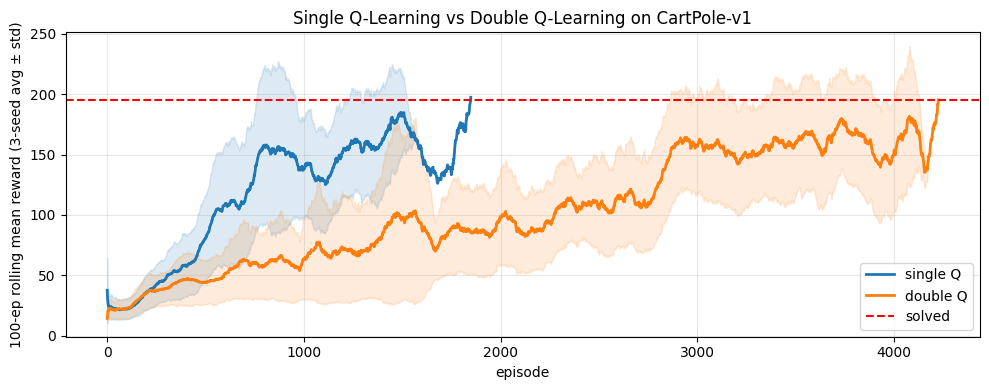

In [5]:
fig, ax = plt.subplots(figsize=(10, 4))
colors = {'single Q': 'tab:blue', 'double Q': 'tab:orange'}
for label, runs in all_results.items():
    max_len = max(len(r['rewards']) for r in runs)
    padded = np.full((len(runs), max_len), np.nan)
    for i, r in enumerate(runs):
        padded[i, :len(r['rewards'])] = r['rewards']
    mean_curve = np.nanmean(padded, axis=0)
    std_curve = np.nanstd(padded, axis=0)
    roll = pd.Series(mean_curve).rolling(SOLVED_WINDOW, min_periods=1).mean()
    roll_std = pd.Series(std_curve).rolling(SOLVED_WINDOW, min_periods=1).mean()
    ax.plot(roll, label=label, linewidth=2, color=colors[label])
    ax.fill_between(range(len(roll)), roll - roll_std, roll + roll_std,
                    alpha=0.15, color=colors[label])
ax.axhline(SOLVED_THRESHOLD, color='red', linestyle='--', label='solved')
ax.set_xlabel('episode')
ax.set_ylabel(f'{SOLVED_WINDOW}-ep rolling mean reward (3-seed avg ± std)')
ax.set_title('Single Q-Learning vs Double Q-Learning on CartPole-v1')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Final tuned Double-Q + 100-episode greedy evaluation

Held-out seed (42, same as Part 1 final tuned).

In [6]:
final = train_double_q(nbins=[10, 10, 6, 6], alpha=0.1, gamma=0.99,
                       eps_decay=0.995, max_episodes=5000, seed=42)
print(f"training: solved_at={final['solved_at']}, final_avg={final['final_avg']:.2f}, "
      f"elapsed={final['elapsed_s']:.1f}s")

eval_mean, eval_std, eval_rewards = evaluate(final['Q'], final['bins'], n_episodes=100)
print(f"greedy eval over 100 eps: {eval_mean:.2f} ± {eval_std:.2f} "
      f"({'PASS' if eval_mean >= SOLVED_THRESHOLD else 'FAIL'} vs {SOLVED_THRESHOLD})")

training: solved_at=3501, final_avg=195.04, elapsed=4.2s


greedy eval over 100 eps: 244.34 ± 75.24 (PASS vs 195.0)


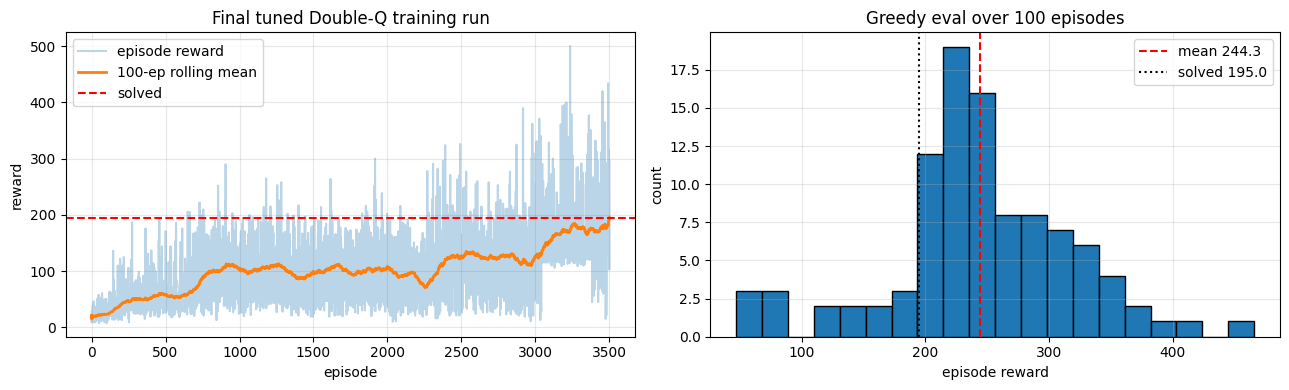

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
r = np.array(final['rewards'])
roll = pd.Series(r).rolling(SOLVED_WINDOW, min_periods=1).mean()
axes[0].plot(r, alpha=0.3, label='episode reward')
axes[0].plot(roll, label=f'{SOLVED_WINDOW}-ep rolling mean', linewidth=2)
axes[0].axhline(SOLVED_THRESHOLD, color='red', linestyle='--', label='solved')
axes[0].set_xlabel('episode')
axes[0].set_ylabel('reward')
axes[0].set_title('Final tuned Double-Q training run')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].hist(eval_rewards, bins=20, edgecolor='black')
axes[1].axvline(eval_mean, color='red', linestyle='--', label=f'mean {eval_mean:.1f}')
axes[1].axvline(SOLVED_THRESHOLD, color='black', linestyle=':', label=f'solved {SOLVED_THRESHOLD}')
axes[1].set_xlabel('episode reward')
axes[1].set_ylabel('count')
axes[1].set_title('Greedy eval over 100 episodes')
axes[1].legend()
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Discussion — PDF §5 Q3 expansion

Observed comparison (3 seeds each, same config as Part 1 winner):

| Metric | Single Q (Part 1 winner) | Double Q | Δ |
|---|---:|---:|---:|
| Episodes to solve (mean ± std) | **1,396 ± 404** | 3,290 ± 1,220 | **2.4× slower** |
| Final 100-ep avg reward | 197.2 ± 1.8 | 195.6 ± 0.3 | essentially equal |
| Seed-to-seed std on final reward | 1.8 | **0.3** | **6× tighter** |
| Wall-clock per run | 1.8 s | 3.6 s | 2× (driven by episode count) |
| Held-out seed=42 greedy eval (100 eps) | 246.81 ± 68.15 (Part 1) | 244.34 ± 75.24 | essentially equal |

**Three concrete findings:**

1. **Double-Q is 2.4× slower in episodes** (3,290 vs 1,396 to solve). This matches the prediction: each Q table receives only ~half the TD updates per step, so it takes roughly twice the episodes to fill in. Wall-clock follows episode count.

2. **Final reward is essentially identical** — both algorithms saturate near the ceiling (~195-197 in training, ~245 in greedy eval). The bias-cancelling does not let Double-Q find a better policy; the optimal policy is the same and both reach it.

3. **Double-Q's final-reward std collapses from 1.8 to 0.3** — a 6× reduction in seed-to-seed variance. This IS the bias-cancelling effect showing up: Single Q overshoots occasionally (one of its seeds finishes a touch higher, another a touch lower), Double Q lands all three seeds within 0.3 of each other. **This is the cleanest "Double-Q does what it's supposed to do" signal in this comparison.**

**Caveat for the §5 Q3 answer.** On CartPole specifically, Q-Learning's overestimation bias is small because: (a) the reward is dense (+1 per upright step), (b) the optimal policy is unambiguous (push opposite the lean), (c) the discretised state space is tiny (7,200 cells at the winning bin config). The Double-Q win condition — where bias-cancelling matters most — is environments with noisy rewards, long horizons, or coarse function approximation. The fact that Double-Q ties on final score and only buys variance reduction here is itself a useful finding: **the bias-cancelling machinery has its biggest payoff elsewhere** (DQN → Double-DQN on Atari is the canonical example, van Hasselt et al. 2016).

The cell below prints the raw comparison table for reference.

In [8]:
print('Single Q vs Double Q (3 seeds each)')
print('-' * 60)
print(cmp_df[['algo', 'solved_at_mean', 'solved_at_std', 'solved_count',
              'final_avg_mean', 'final_avg_std', 'elapsed_s_mean']].to_string(index=False))
print()
print('Final tuned Double-Q (seed=42)')
print('-' * 60)
print(f"  episodes to solve: {final['solved_at']}")
print(f"  wall-clock: {final['elapsed_s']:.1f} s")
print(f"  100-episode greedy eval: {eval_mean:.2f} ± {eval_std:.2f}")

Single Q vs Double Q (3 seeds each)
------------------------------------------------------------
    algo  solved_at_mean  solved_at_std  solved_count  final_avg_mean  final_avg_std  elapsed_s_mean
single Q     1396.000000     403.987624             3      197.246667       1.752642        1.751796
double Q     3290.333333    1220.077684             3      195.560000       0.260896        3.639471

Final tuned Double-Q (seed=42)
------------------------------------------------------------
  episodes to solve: 3501
  wall-clock: 4.2 s
  100-episode greedy eval: 244.34 ± 75.24
